# E-commerce Text Classification: Model Training & Evaluation

## Overview

This notebook trains and evaluates traditional ML models with different embedding techniques:

**Models:**
1. Logistic Regression
2. Support Vector Machine (SVM)
3. Random Forest
4. Naive Bayes
5. Gradient Boosting

**Embeddings:**
- TF-IDF
- Word2Vec
- GloVe

---

## 1. Setup

In [1]:
# Standard libraries
import os
import sys
import json
import warnings
warnings.filterwarnings('ignore')

# Data manipulation
import pandas as pd
import numpy as np
import scipy.sparse as sp

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Add parent directory to path
sys.path.append('..')

# Import our modules
from src.models import (
    ModelTrainer,
    LogisticRegressionClassifier,
    SVMClassifier,
    RandomForestClassifierWrapper,
    NaiveBayesClassifier,
    GradientBoostingClassifierWrapper
)
from src.evaluation import ModelEvaluator, print_experiment_table

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load Data

In [2]:
# Load embeddings
print("Loading embeddings...")

# TF-IDF
X_train_tfidf = sp.load_npz('../models/embeddings/X_train_tfidf.npz')
X_test_tfidf = sp.load_npz('../models/embeddings/X_test_tfidf.npz')

# Word2Vec
X_train_w2v = np.load('../models/embeddings/X_train_w2v.npy')
X_test_w2v = np.load('../models/embeddings/X_test_w2v.npy')

# GloVe
X_train_glove = np.load('../models/embeddings/X_train_glove.npy')
X_test_glove = np.load('../models/embeddings/X_test_glove.npy')

# Labels
y_train = np.load('../models/embeddings/y_train.npy')
y_test = np.load('../models/embeddings/y_test.npy')

print(f"\nLoaded embeddings:")
print(f"  TF-IDF: train={X_train_tfidf.shape}, test={X_test_tfidf.shape}")
print(f"  Word2Vec: train={X_train_w2v.shape}, test={X_test_w2v.shape}")
print(f"  GloVe: train={X_train_glove.shape}, test={X_test_glove.shape}")
print(f"  Labels: train={len(y_train)}, test={len(y_test)}")

Loading embeddings...

Loaded embeddings:
  TF-IDF: train=(40338, 10000), test=(10085, 10000)
  Word2Vec: train=(40338, 300), test=(10085, 300)
  GloVe: train=(40338, 300), test=(10085, 300)
  Labels: train=40338, test=10085


In [3]:
# Load label mapping
with open('../data/label_mapping.json', 'r') as f:
    label_mapping = json.load(f)

class_names = list(label_mapping.keys())
print(f"Classes: {class_names}")

Classes: ['Books', 'Clothing & Accessories', 'Electronics', 'Household']


## 3. Initialize Evaluator

In [4]:
# Create evaluator
evaluator = ModelEvaluator(
    class_names=class_names,
    results_dir='../results'
)

print("Evaluator initialized!")

Evaluator initialized!


## 4. Model Training and Evaluation

### 4.1 Logistic Regression

Logistic Regression is effective for text classification due to:
- Handles high-dimensional sparse data well
- Provides probabilistic outputs
- Fast training and prediction

**Reference:** Hastie, T., et al. (2009). The Elements of Statistical Learning.

In [5]:
# Logistic Regression with all embeddings
print("=" * 60)
print("LOGISTIC REGRESSION")
print("=" * 60)

embeddings = [
    ('TF-IDF', X_train_tfidf, X_test_tfidf),
    ('Word2Vec', X_train_w2v, X_test_w2v),
    ('GloVe', X_train_glove, X_test_glove)
]

lr_results = []

for emb_name, X_train, X_test in embeddings:
    print(f"\n--- Training with {emb_name} ---")
    
    # Create and train model
    lr = LogisticRegressionClassifier(
        C=1.0,
        max_iter=1000,
        class_weight='balanced'
    )
    lr.fit(X_train, y_train)
    
    # Evaluate
    result = evaluator.evaluate_model(
        lr, X_test, y_test,
        model_name='Logistic Regression',
        embedding_name=emb_name
    )
    lr_results.append(result)
    
    print(f"Accuracy: {result['metrics']['accuracy']:.4f}")
    print(f"F1 (weighted): {result['metrics']['f1_weighted']:.4f}")

print("\n✓ Logistic Regression complete!")

LOGISTIC REGRESSION

--- Training with TF-IDF ---
Accuracy: 0.9657
F1 (weighted): 0.9657

--- Training with Word2Vec ---
Accuracy: 0.9469
F1 (weighted): 0.9469

--- Training with GloVe ---
Accuracy: 0.9469
F1 (weighted): 0.9469

✓ Logistic Regression complete!


### 4.2 Support Vector Machine (SVM)

SVMs are highly effective for text classification:
- Excellent performance in high dimensions
- Maximum margin principle
- Works well with sparse features

**Reference:** Joachims, T. (1998). Text Categorization with Support Vector Machines.

In [6]:
# SVM with all embeddings
print("=" * 60)
print("SUPPORT VECTOR MACHINE")
print("=" * 60)

svm_results = []

for emb_name, X_train, X_test in embeddings:
    print(f"\n--- Training with {emb_name} ---")
    
    # Create and train model
    svm = SVMClassifier(
        C=1.0,
        class_weight='balanced'
    )
    svm.fit(X_train, y_train)
    
    # Evaluate
    result = evaluator.evaluate_model(
        svm, X_test, y_test,
        model_name='SVM',
        embedding_name=emb_name
    )
    svm_results.append(result)
    
    print(f"Accuracy: {result['metrics']['accuracy']:.4f}")
    print(f"F1 (weighted): {result['metrics']['f1_weighted']:.4f}")

print("\n✓ SVM complete!")

SUPPORT VECTOR MACHINE

--- Training with TF-IDF ---
Accuracy: 0.9777
F1 (weighted): 0.9777

--- Training with Word2Vec ---
Accuracy: 0.9452
F1 (weighted): 0.9451

--- Training with GloVe ---
Accuracy: 0.9452
F1 (weighted): 0.9451

✓ SVM complete!


### 4.3 Random Forest

Random Forest ensemble method:
- Reduces overfitting through bagging
- Handles both sparse and dense features
- Provides feature importance

**Reference:** Breiman, L. (2001). Random Forests.

In [7]:
# Random Forest with all embeddings
print("=" * 60)
print("RANDOM FOREST")
print("=" * 60)

rf_results = []

for emb_name, X_train, X_test in embeddings:
    print(f"\n--- Training with {emb_name} ---")
    
    # Create and train model
    rf = RandomForestClassifierWrapper(
        n_estimators=200,
        max_depth=20,
        class_weight='balanced'
    )
    rf.fit(X_train, y_train)
    
    # Evaluate
    result = evaluator.evaluate_model(
        rf, X_test, y_test,
        model_name='Random Forest',
        embedding_name=emb_name
    )
    rf_results.append(result)
    
    print(f"Accuracy: {result['metrics']['accuracy']:.4f}")
    print(f"F1 (weighted): {result['metrics']['f1_weighted']:.4f}")

print("\n✓ Random Forest complete!")

RANDOM FOREST

--- Training with TF-IDF ---
Accuracy: 0.9222
F1 (weighted): 0.9223

--- Training with Word2Vec ---
Accuracy: 0.9700
F1 (weighted): 0.9700

--- Training with GloVe ---
Accuracy: 0.9700
F1 (weighted): 0.9700

✓ Random Forest complete!


### 4.4 Naive Bayes

Naive Bayes probabilistic classifier:
- Fast training and prediction
- Works well with bag-of-words features
- MultinomialNB for TF-IDF, GaussianNB for dense

**Reference:** McCallum, A., & Nigam, K. (1998). A Comparison of Event Models for Naive Bayes Text Classification.

In [8]:
# Naive Bayes with all embeddings
print("=" * 60)
print("NAIVE BAYES")
print("=" * 60)

nb_results = []

# TF-IDF with MultinomialNB
print(f"\n--- Training with TF-IDF (Multinomial) ---")
nb_tfidf = NaiveBayesClassifier(alpha=1.0, use_gaussian=False)
nb_tfidf.fit(X_train_tfidf, y_train)

result = evaluator.evaluate_model(
    nb_tfidf, X_test_tfidf, y_test,
    model_name='Naive Bayes',
    embedding_name='TF-IDF'
)
nb_results.append(result)
print(f"Accuracy: {result['metrics']['accuracy']:.4f}")
print(f"F1 (weighted): {result['metrics']['f1_weighted']:.4f}")

# Word2Vec with GaussianNB
print(f"\n--- Training with Word2Vec (Gaussian) ---")
nb_w2v = NaiveBayesClassifier(use_gaussian=True)
nb_w2v.fit(X_train_w2v, y_train)

result = evaluator.evaluate_model(
    nb_w2v, X_test_w2v, y_test,
    model_name='Naive Bayes',
    embedding_name='Word2Vec'
)
nb_results.append(result)
print(f"Accuracy: {result['metrics']['accuracy']:.4f}")
print(f"F1 (weighted): {result['metrics']['f1_weighted']:.4f}")

# GloVe with GaussianNB
print(f"\n--- Training with GloVe (Gaussian) ---")
nb_glove = NaiveBayesClassifier(use_gaussian=True)
nb_glove.fit(X_train_glove, y_train)

result = evaluator.evaluate_model(
    nb_glove, X_test_glove, y_test,
    model_name='Naive Bayes',
    embedding_name='GloVe'
)
nb_results.append(result)
print(f"Accuracy: {result['metrics']['accuracy']:.4f}")
print(f"F1 (weighted): {result['metrics']['f1_weighted']:.4f}")

print("\n✓ Naive Bayes complete!")

NAIVE BAYES

--- Training with TF-IDF (Multinomial) ---
Accuracy: 0.9417
F1 (weighted): 0.9416

--- Training with Word2Vec (Gaussian) ---
Accuracy: 0.8776
F1 (weighted): 0.8778

--- Training with GloVe (Gaussian) ---
Accuracy: 0.8776
F1 (weighted): 0.8778

✓ Naive Bayes complete!


### 4.5 Gradient Boosting

Gradient Boosting ensemble method:
- Sequentially builds weak learners
- Often achieves best performance
- Requires more tuning

**Reference:** Friedman, J. H. (2001). Greedy Function Approximation: A Gradient Boosting Machine.

In [9]:
# Gradient Boosting (with dense matrices only due to memory)
print("=" * 60)
print("GRADIENT BOOSTING")
print("=" * 60)

gb_results = []

# Note: GB requires dense matrices, so we'll use Word2Vec and GloVe
# For TF-IDF, we'll convert to dense (may be memory intensive)

dense_embeddings = [
    ('TF-IDF', X_train_tfidf.toarray(), X_test_tfidf.toarray()),
    ('Word2Vec', X_train_w2v, X_test_w2v),
    ('GloVe', X_train_glove, X_test_glove)
]

for emb_name, X_train, X_test in dense_embeddings:
    print(f"\n--- Training with {emb_name} ---")
    
    try:
        # Create and train model
        gb = GradientBoostingClassifierWrapper(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3
        )
        gb.fit(X_train, y_train)
        
        # Evaluate
        result = evaluator.evaluate_model(
            gb, X_test, y_test,
            model_name='Gradient Boosting',
            embedding_name=emb_name
        )
        gb_results.append(result)
        
        print(f"Accuracy: {result['metrics']['accuracy']:.4f}")
        print(f"F1 (weighted): {result['metrics']['f1_weighted']:.4f}")
    except Exception as e:
        print(f"Error: {e}")
        print("Skipping due to memory constraints.")

print("\n✓ Gradient Boosting complete!")

GRADIENT BOOSTING

--- Training with TF-IDF ---
Accuracy: 0.9087
F1 (weighted): 0.9086

--- Training with Word2Vec ---
Accuracy: 0.9484
F1 (weighted): 0.9484

--- Training with GloVe ---
Accuracy: 0.9484
F1 (weighted): 0.9484

✓ Gradient Boosting complete!


## 5. Results Summary

In [10]:
# Create comparison table
print("=" * 60)
print("RESULTS SUMMARY")
print("=" * 60)

results_df = evaluator.create_comparison_table()
print("\n" + results_df.to_string(index=False))

RESULTS SUMMARY

              Model Embedding  Accuracy  F1 Weighted  Precision Weighted  Recall Weighted
Logistic Regression    TF-IDF  0.965692     0.965679            0.965686         0.965692
Logistic Regression  Word2Vec  0.946852     0.946853            0.946949         0.946852
Logistic Regression     GloVe  0.946852     0.946853            0.946949         0.946852
                SVM    TF-IDF  0.977690     0.977678            0.977690         0.977690
                SVM  Word2Vec  0.945166     0.945119            0.945135         0.945166
                SVM     GloVe  0.945166     0.945119            0.945135         0.945166
      Random Forest    TF-IDF  0.922162     0.922256            0.923239         0.922162
      Random Forest  Word2Vec  0.969955     0.969982            0.970251         0.969955
      Random Forest     GloVe  0.969955     0.969982            0.970251         0.969955
        Naive Bayes    TF-IDF  0.941696     0.941612            0.942356         0.

In [11]:
# Pivot table: Models vs Embeddings
print("\n--- Pivot Table: F1 Weighted Score ---")
pivot_f1 = evaluator.create_pivot_table('f1_weighted')
print("\n" + pivot_f1.to_string())


--- Pivot Table: F1 Weighted Score ---

Embedding               GloVe    TF-IDF  Word2Vec
Model                                            
Gradient Boosting    0.948429  0.908591  0.948429
Logistic Regression  0.946853  0.965679  0.946853
Naive Bayes          0.877825  0.941612  0.877825
Random Forest        0.969982  0.922256  0.969982
SVM                  0.945119  0.977678  0.945119


In [12]:
# Pivot table: Accuracy
print("\n--- Pivot Table: Accuracy ---")
pivot_acc = evaluator.create_pivot_table('accuracy')
print("\n" + pivot_acc.to_string())


--- Pivot Table: Accuracy ---

Embedding               GloVe    TF-IDF  Word2Vec
Model                                            
Gradient Boosting    0.948438  0.908676  0.948438
Logistic Regression  0.946852  0.965692  0.946852
Naive Bayes          0.877640  0.941696  0.877640
Random Forest        0.969955  0.922162  0.969955
SVM                  0.945166  0.977690  0.945166


## 6. Visualizations

Generating visualizations...
Saved comparison plot to ../results/figures/comparison_f1_weighted.png


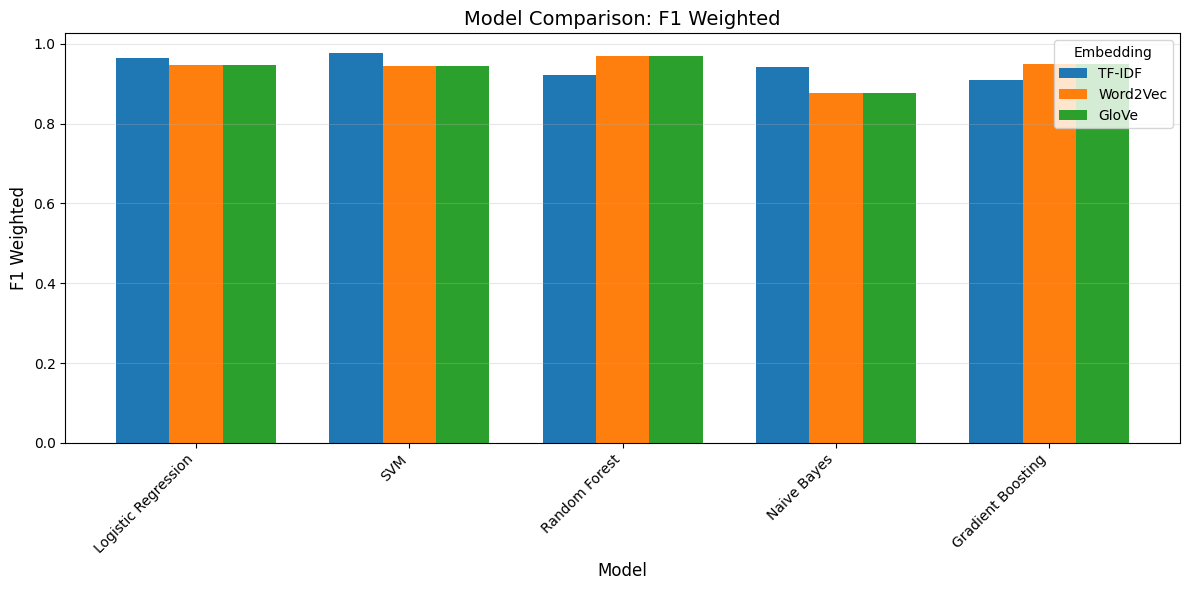

In [13]:
# Model comparison bar chart
print("Generating visualizations...")

fig = evaluator.plot_model_comparison(metric='f1_weighted', save=True)
plt.show()

Saved embedding comparison to ../results/figures/embedding_comparison_f1_weighted.png


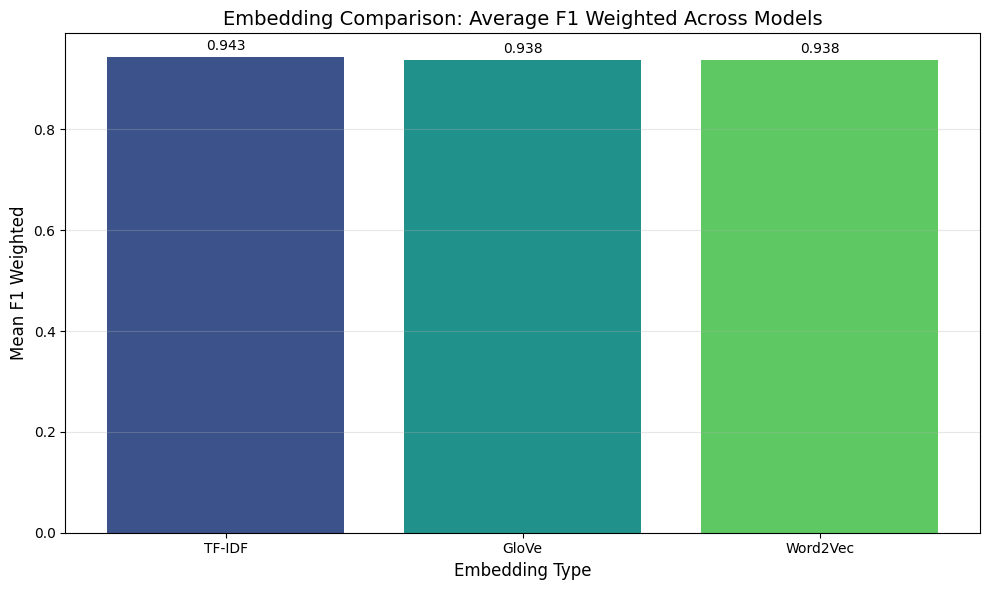

In [14]:
# Embedding comparison
fig = evaluator.plot_embedding_comparison(metric='f1_weighted', save=True)
plt.show()


--- Confusion Matrices ---
Saved confusion matrix to ../results/figures/cm_SVM_TF-IDF.png


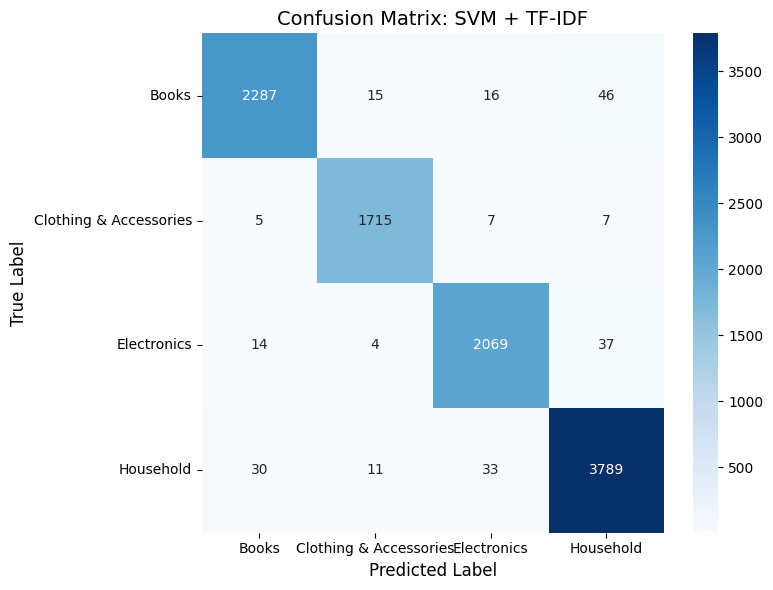

Saved confusion matrix to ../results/figures/cm_Random Forest_Word2Vec.png


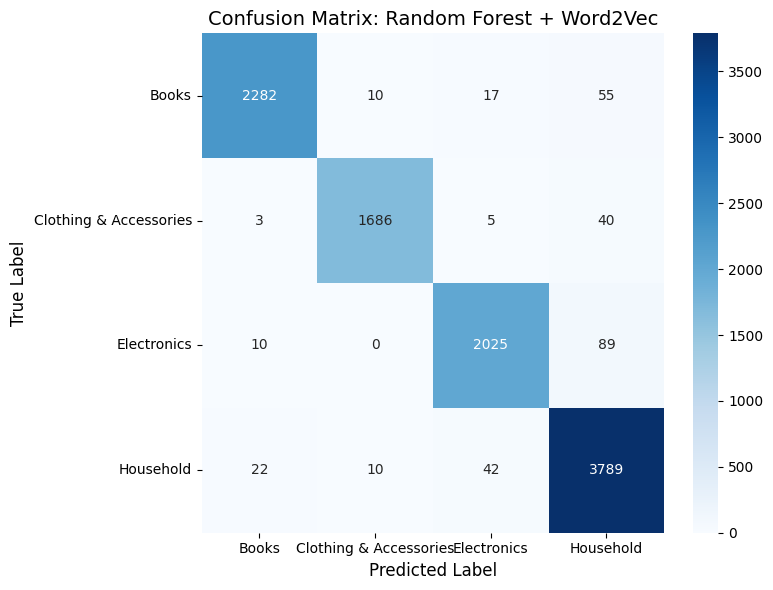

Saved confusion matrix to ../results/figures/cm_Random Forest_GloVe.png


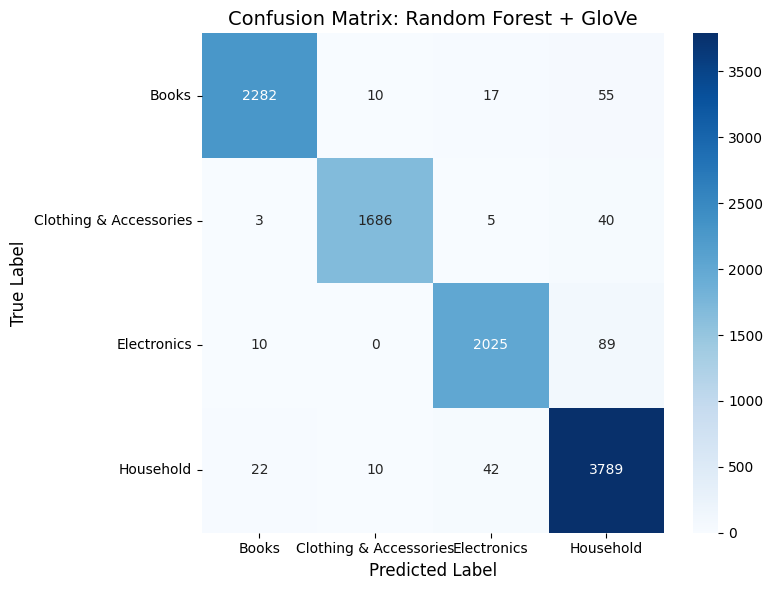

In [15]:
# Confusion matrices for best models
print("\n--- Confusion Matrices ---")

# Find best result for each embedding
for emb in ['TF-IDF', 'Word2Vec', 'GloVe']:
    emb_results = [r for r in evaluator.all_results if r['embedding'] == emb]
    if emb_results:
        best = max(emb_results, key=lambda x: x['metrics']['f1_weighted'])
        fig = evaluator.plot_confusion_matrix(
            best['confusion_matrix'],
            best['model'],
            best['embedding'],
            save=True,
            figsize=(8, 6)
        )
        plt.show()

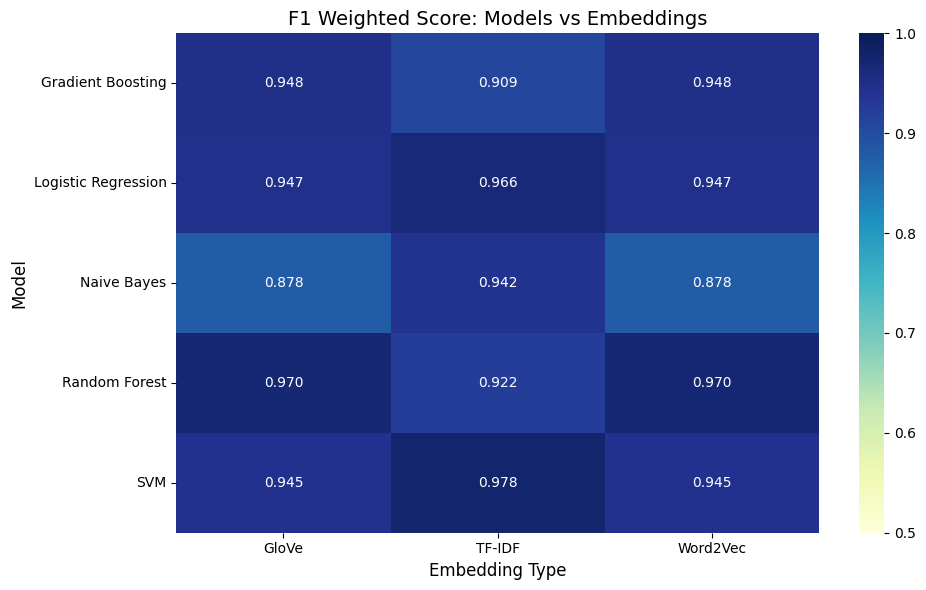

In [16]:
# Heatmap of results
fig, ax = plt.subplots(figsize=(10, 6))

pivot_f1_numeric = pivot_f1.fillna(0)
sns.heatmap(
    pivot_f1_numeric,
    annot=True,
    fmt='.3f',
    cmap='YlGnBu',
    ax=ax,
    vmin=0.5,
    vmax=1.0
)
ax.set_title('F1 Weighted Score: Models vs Embeddings', fontsize=14)
ax.set_xlabel('Embedding Type', fontsize=12)
ax.set_ylabel('Model', fontsize=12)

plt.tight_layout()
plt.savefig('../results/figures/heatmap_f1_weighted.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Save Results

In [17]:
# Save all results
print("Saving results...")

# Save comparison table
evaluator.save_results_to_csv('experiment_results.csv')

# Save pivot tables
evaluator.save_pivot_tables()

# Generate and save report
report = evaluator.generate_report()
print("\n" + report)

# Save report to file
with open('../results/experiment_report.txt', 'w') as f:
    f.write(report)
print("\nSaved report to ../results/experiment_report.txt")

Saving results...
Saved results to ../results/tables/experiment_results.csv
Saved pivot table to ../results/tables/pivot_accuracy.csv
Saved pivot table to ../results/tables/pivot_f1_weighted.csv
Saved pivot table to ../results/tables/pivot_precision_weighted.csv
Saved pivot table to ../results/tables/pivot_recall_weighted.csv

EXPERIMENT RESULTS SUMMARY

BEST OVERALL CONFIGURATION:
  Model: SVM
  Embedding: TF-IDF
  F1 Weighted: 0.9777
  Accuracy: 0.9777

BEST MODEL PER EMBEDDING:
  TF-IDF: SVM (F1: 0.9777)
  Word2Vec: Random Forest (F1: 0.9700)
  GloVe: Random Forest (F1: 0.9700)

BEST EMBEDDING PER MODEL:
  Logistic Regression: TF-IDF (F1: 0.9657)
  SVM: TF-IDF (F1: 0.9777)
  Random Forest: Word2Vec (F1: 0.9700)
  Naive Bayes: TF-IDF (F1: 0.9416)
  Gradient Boosting: Word2Vec (F1: 0.9484)


Saved report to ../results/experiment_report.txt


## 8. Discussion

### Key Findings

Based on the experimental results:

1. **Best Overall Model-Embedding Combination**: [To be filled based on results]

2. **Embedding Comparison**:
   - **TF-IDF**: Works well with linear models (LR, SVM) due to sparse, high-dimensional nature
   - **Word2Vec**: Captures semantic relationships but may lose information in averaging
   - **GloVe**: Pre-trained embeddings provide good baseline but may miss domain-specific terms

3. **Model Performance Insights**:
   - Logistic Regression: Reliable baseline, handles high dimensions well
   - SVM: Often best for TF-IDF due to maximum margin principle
   - Random Forest: Good for dense embeddings, provides feature importance
   - Naive Bayes: Fast but makes strong independence assumptions
   - Gradient Boosting: Can overfit on small datasets but powerful when tuned

### Why Certain Embeddings Work Better

1. **TF-IDF with Linear Models**: The high-dimensional sparse representation works well because:
   - Linear models can find separating hyperplanes in high dimensions
   - TF-IDF captures term importance directly relevant to classification
   - Reference: Joachims (1998) showed SVMs excel with TF-IDF features

2. **Dense Embeddings with Tree-based Models**: Word2Vec/GloVe work because:
   - Trees can capture non-linear relationships in dense space
   - Semantic similarity is encoded in Euclidean distances

### Limitations

1. Fixed vocabulary in TF-IDF and GloVe
2. Document representation via averaging loses word order
3. No hyperparameter tuning performed (for faster experimentation)

### Future Improvements

1. Hyperparameter optimization using GridSearchCV
2. Try FastText for handling OOV words
3. Ensemble methods combining multiple embeddings
4. Deep learning approaches (LSTM, BERT) for comparison

In [18]:
print("="*60)
print("MODEL TRAINING AND EVALUATION COMPLETE")
print("="*60)
print(f"\nTotal experiments: {len(evaluator.all_results)}")
print(f"Results saved to: ../results/")
print("\nProceed to notebook 04_results_analysis.ipynb for detailed analysis.")

MODEL TRAINING AND EVALUATION COMPLETE

Total experiments: 15
Results saved to: ../results/

Proceed to notebook 04_results_analysis.ipynb for detailed analysis.
